# tiny_umm：训练结果与交互式演示

本 notebook 使用正式训练 checkpoint 和验证集。图片与数值已运行并保存；修改参数后可依次重新运行。raw 是 Flow 原始输出，constrained 在源图估计区域外复制源像素；GT 仅用于展示和评估。

评估采用固定随机种子、128 个验证场景和 40 步采样；不是完整测试集结果。

In [1]:
from pathlib import Path
import os, json, numpy as np, matplotlib.pyplot as plt, torch
root = Path.cwd()
if not (root / 'configs/default.yaml').exists():
    root = root.parent
os.chdir(root)
from data.schema import load_config, get_device
from data.dataset import load_group
from inference import Pipeline, predict_understanding
from models.checkpoints import load_understanding
cfg = load_config()
device = get_device(cfg)
print('Project:', root.resolve(), '| device:', device)
print('Validation report: 128 scenes, 40 steps')
report = json.loads(Path('artifacts/outputs/notebook_val.json').read_text(encoding='utf-8'))['splits']['val']
for name, row in report['variants'].items():
    gen, edit = row['generation']['oracle'], row['editing']['constrained']
    print(f"{name:16} generation joint={gen['joint_accuracy']:.1%} (parse={gen['parse_rate']:.1%}); "
          f"edit joint={edit['joint_accuracy']:.1%}, count preserved={edit['count_preservation']:.1%} (parse={edit['parse_rate']:.1%})")
print(f"Understanding joint on these 128 scenes: {report['understanding']['joint_accuracy']:.1%}")

Project: E:\code\tiny_umm | device: cuda
Validation report: 128 scenes, 40 steps
gold_structured  generation joint=54.7% (parse=78.9%); edit joint=78.1%, count preserved=98.4% (parse=85.9%)
connector        generation joint=54.7% (parse=78.9%); edit joint=43.8%, count preserved=56.2% (parse=78.9%)
Understanding joint on these 128 scenes: 74.2%


## 训练曲线

理解模型比较有无增强的验证集 joint；Flow 对照的编辑曲线分别使用各自的默认源像素设置，因此并非完全相同的推理条件。connector 使用冻结 Flow、无源像素直通。

Augmentation: best validation joint = 79.32%
No augmentation: best validation joint = 73.58%
Flow with direct source: best val edit FM = 0.0437
Flow without direct source: best val edit FM = 0.0444
Connector: best val edit FM = 0.0648


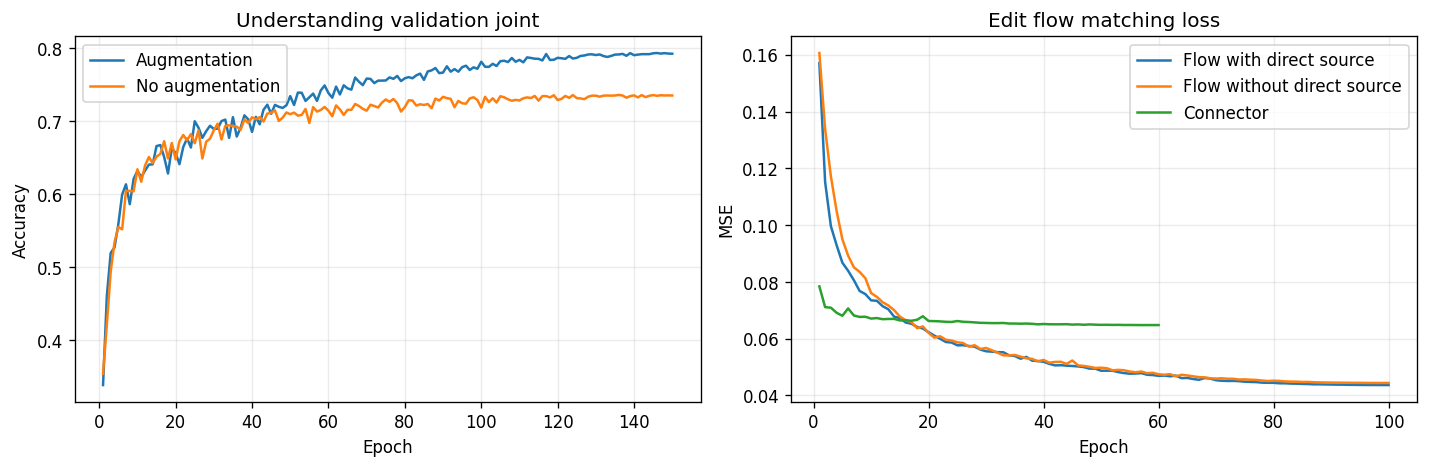

In [3]:
def history(path):
    return json.loads(Path(path).read_text(encoding='utf-8'))
a = history('artifacts/outputs/understanding_history.json')
a0 = history('artifacts/outputs/tensorboard/experiments/no_augmentation/understanding_history.json')
b = history('artifacts/outputs/flow_history.json')
b0 = history('artifacts/outputs/tensorboard/experiments/no_direct/flow_history.json')
c = history('artifacts/outputs/connector_history.json')
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for rows, name in [(a, 'Augmentation'), (a0, 'No augmentation')]:
    ax[0].plot([r['epoch'] for r in rows], [r['val/joint_accuracy'] for r in rows], label=name)
    print(f"{name}: best validation joint = {max(r['val/joint_accuracy'] for r in rows):.2%}")
for rows, name in [(b, 'Flow with direct source'), (b0, 'Flow without direct source'), (c, 'Connector')]:
    ax[1].plot([r['epoch'] for r in rows], [r['val/edit_fm'] for r in rows], label=name)
    print(f"{name}: best val edit FM = {min(r['val/edit_fm'] for r in rows):.4f}")
ax[0].set(title='Understanding validation joint', xlabel='Epoch', ylabel='Accuracy')
ax[1].set(title='Edit flow matching loss', xlabel='Epoch', ylabel='MSE')
for a_ in ax: a_.legend(); a_.grid(alpha=.25)
fig.tight_layout()
plt.show()

## 理解、生成与编辑示例

每行是同一个验证场景：源图及理解预测、生成结果、编辑目标、原始编辑和约束编辑。生成是从噪声采样的独立场景，无需与源图布局一致。可修改 indices、steps 和 seed 重新采样。

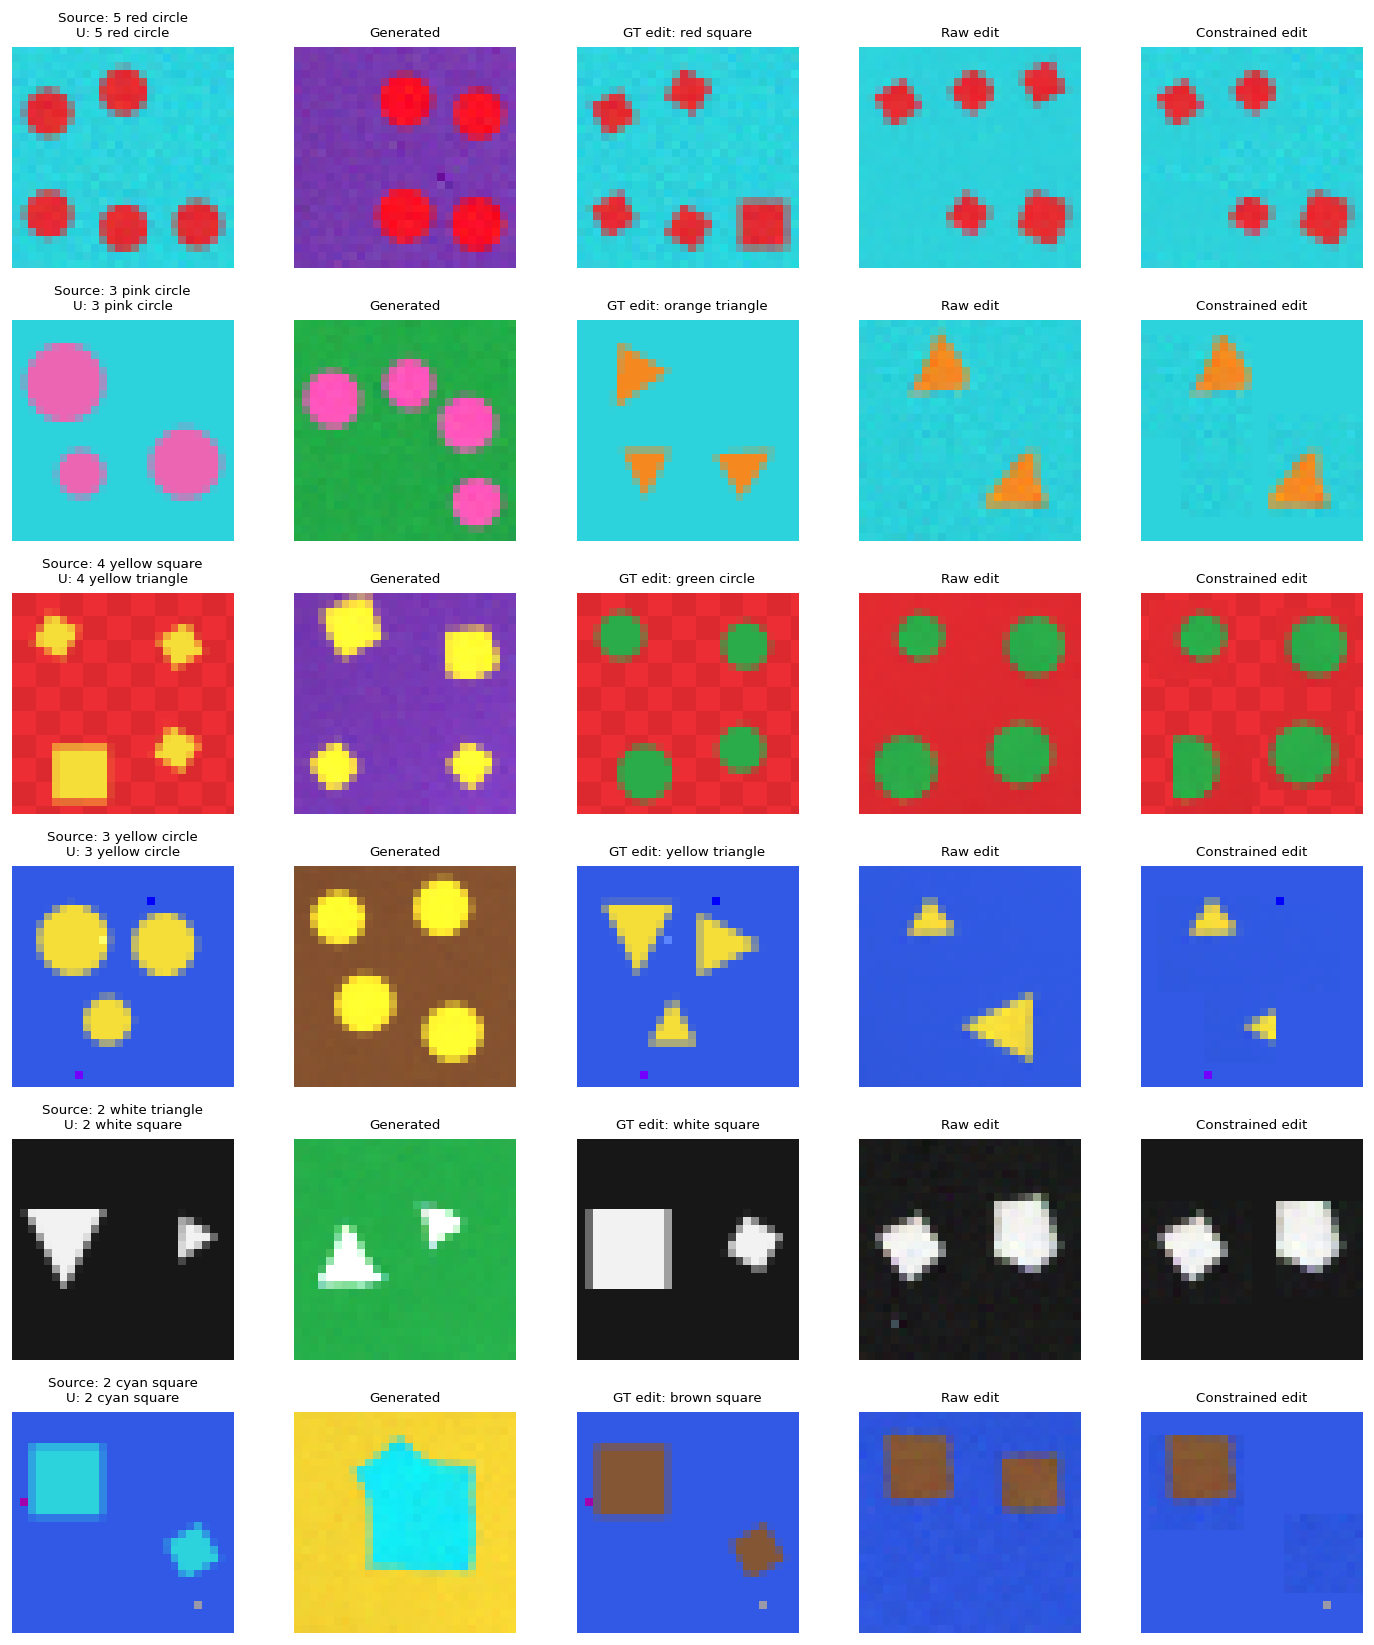

In [5]:
data = load_group(cfg, 'val')
indices = np.array([0, 3, 8, 12, 25, 38])
steps, seed = 40, 123
source = data['images'][indices]
u = load_understanding(cfg, device)
pred = predict_understanding(u, source, cfg, device)
pipe = Pipeline(cfg, device)
generated = pipe.generate(data['prompts_gen'][indices], steps=steps, seed=seed)
edited = pipe.edit(source, data['prompts_edit'][indices], steps=steps, seed=seed+1)
fig, axes = plt.subplots(len(indices), 5, figsize=(12, 2.3*len(indices)))
for j, i in enumerate(indices):
    truth = f"{data['counts'][i]} {cfg['colors']['names'][data['colors'][i]]} {cfg['shapes']['names'][data['shapes'][i]]}"
    guess = f"{pred['count'][j]+1} {cfg['colors']['names'][pred['color'][j]]} {cfg['shapes']['names'][pred['shape'][j]]}"
    target = f"{cfg['colors']['names'][data['edit_colors'][i]]} {cfg['shapes']['names'][data['edit_shapes'][i]]}"
    imgs = [source[j], generated[j], data['edit_targets'][i], edited.raw[j], edited.constrained[j]]
    titles = [f"Source: {truth}\nU: {guess}", 'Generated', f"GT edit: {target}", 'Raw edit', 'Constrained edit']
    for ax, im, title in zip(axes[j], imgs, titles):
        ax.imshow(im); ax.set_title(title, fontsize=8); ax.axis('off')
fig.tight_layout()
plt.show()

无法解析的图像计入准确率分母；parse_rate 表示规则 oracle 能同时解析数量、颜色和形状的比例。报告中的 GT 区域仅用于离线评分，不参与正常编辑推理。完整曲线也可在 [TensorBoard](http://127.0.0.1:6006/) 中查看。